# PS-O3: Knapsack Relief — QAOA and Architecture Co-design

Run all cells from the repository root. Phase 1: A/B only. No quantum hardware credentials required.

The five-item hinge Hamiltonian is higher-order, not QUBO. The full slack-variable QUBO has nine qubits, runs on B and exceeds A capacity.

In [1]:
from pathlib import Path
import sys
assert Path("run_experiment.py").exists(), "Open notebook from submission root"
from src.problem import brute_force, validate, qubo
validate(), brute_force()["solutions"]

## Formulation
Maximize sum(v_i x_i), weight <= 15.

True QUBO: -sum(v_i x_i)+2*(sum(w_i x_i)+s-15)^2, s=y0+2*y1+4*y2+8*y3. Penalty 2 is validated for this exact instance, not a universal constant. All 512 assignments are checked. Minimizing over slack yields the exact squared-overflow cost on the 32 item assignments.

In [2]:
qubo()

## End-to-end experiment
Seeded multistart p=1 angle search, explicit Pauli synthesis, Qiskit/NumPy equivalence, SABRE compilation, 4096 ideal/noisy shots, and all exports. This may take several minutes.

In [3]:
import subprocess
completed = subprocess.run([sys.executable,"run_experiment.py"],capture_output=True,text=True)
print(completed.stdout)
if completed.returncode:
    raise RuntimeError(completed.stderr)

Exact NumPy QAOA hinge: {'items': [2, 3, 4, 5], 'weight': 15, 'value': 24, 'feasible': True}; valid=0.7825
Exact NumPy QAOA slack: {'items': [4, 5], 'weight': 8, 'value': 13, 'feasible': True}; valid=0.9524
A hinge ideal: depth=192 CX=186 swaps=34 valid=0.7842
A hinge noisy: depth=192 CX=186 swaps=34 valid=0.8354
B hinge ideal: depth=140 CX=105 swaps=3 valid=0.7861
B hinge noisy: depth=140 CX=105 swaps=3 valid=0.8225
B slack ideal: depth=111 CX=117 swaps=15 valid=0.9504
B slack noisy: depth=111 CX=117 swaps=15 valid=0.9387
Qiskit statevector equivalence, routed equivalence, physical-edge checks and A/B benchmarks passed.



In [4]:
import json
rows=json.loads(Path("results/tables/benchmark.json").read_text())
for row in rows:
    print(row["processor"],row["encoding"],row["mode"],row["selected"],"depth",row["depth"],"CX",row["cx_count"],"SWAP",row["routing_swaps"],"P(valid)",row["probability_valid"])

A hinge ideal {'items': [1, 2, 3, 4], 'weight': 14, 'value': 26, 'feasible': True} depth 192 CX 186 SWAP 34 P(valid) 0.7841796875
A hinge noisy {'items': [2, 3, 4, 5], 'weight': 15, 'value': 24, 'feasible': True} depth 192 CX 186 SWAP 34 P(valid) 0.83544921875
B hinge ideal {'items': [1, 2, 3, 4], 'weight': 14, 'value': 26, 'feasible': True} depth 140 CX 105 SWAP 3 P(valid) 0.7861328125
B hinge noisy {'items': [2, 3, 4, 5], 'weight': 15, 'value': 24, 'feasible': True} depth 140 CX 105 SWAP 3 P(valid) 0.822509765625
B slack ideal {'items': [2, 5], 'weight': 9, 'value': 12, 'feasible': True} depth 111 CX 117 SWAP 15 P(valid) 0.950439453125
B slack noisy {'items': [5], 'weight': 6, 'value': 8, 'feasible': True} depth 111 CX 117 SWAP 15 P(valid) 0.938720703125


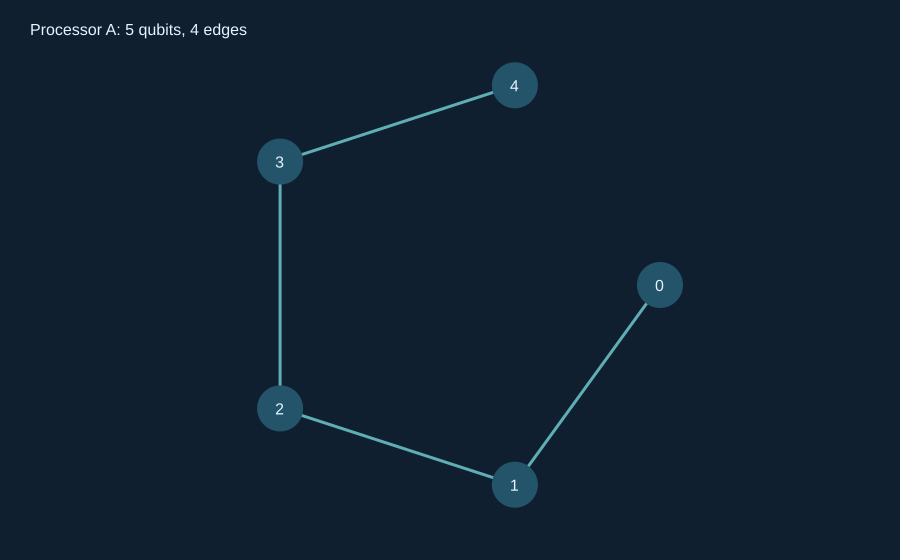

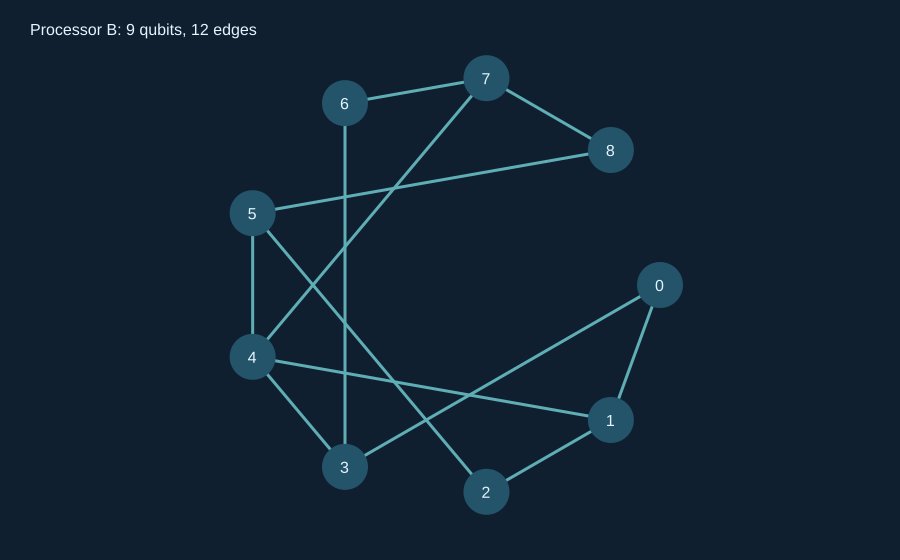

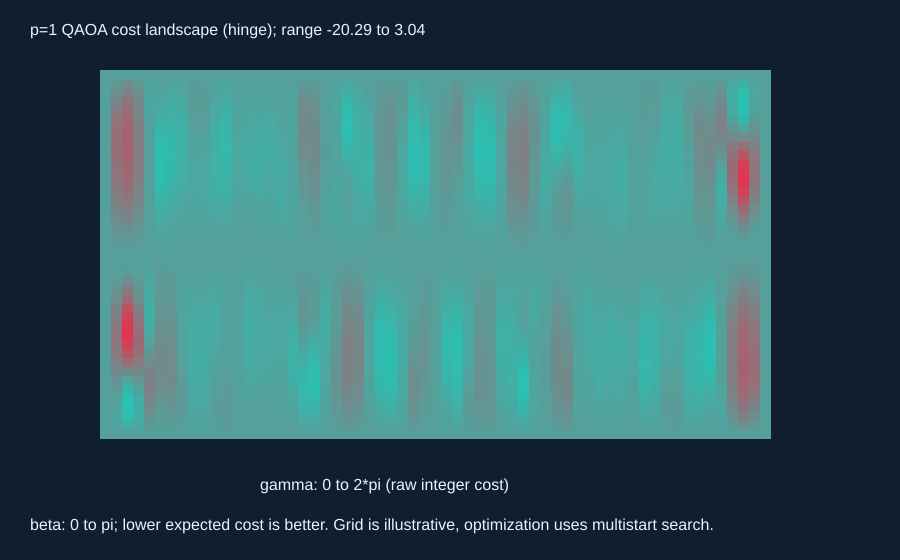

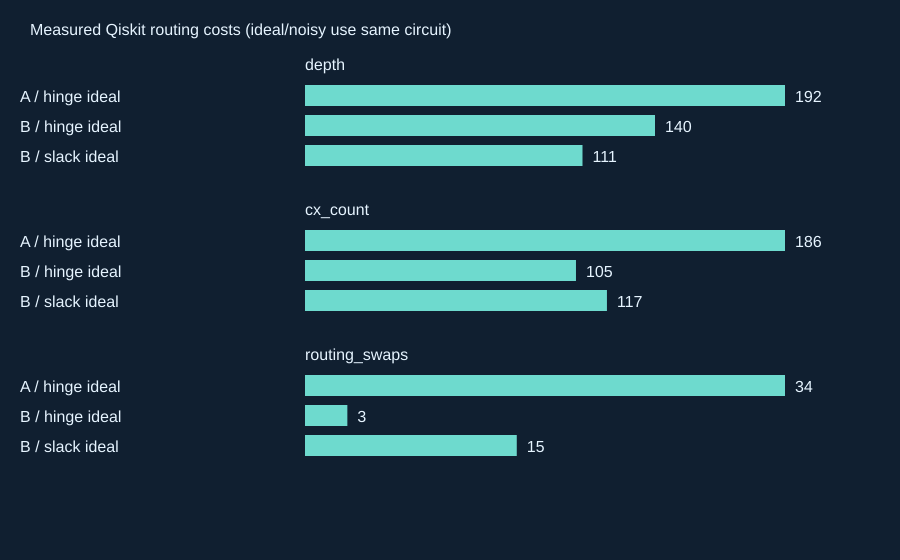

In [5]:
for figure in ["topology_A.svg","topology_B.svg","qaoa_landscape.svg","routing_comparison.svg"]:
    display({"image/svg+xml":Path("results/figures/"+figure).read_text()},raw=True)

## Interpretation
Compare hinge A versus hinge B with identical angles and noise. B/slack is a distinct larger encoding, not a controlled connectivity-only comparison. Selected value is postselected on feasibility; report unconditional P(valid) and P(optimal) as well. A shallow simulator result does not establish quantum advantage. See report.md.

## Reproducibility and bonus analyses

Six same-seed raw-count replays matched exactly. Three additional simulator seeds retain fixed layout/angles. Penalty analysis checks classical ground-state safety; confidence intervals quantify shot uncertainty.

In [6]:
from reproduce import verify
from analyze import main as analyze
analyze()
print(verify())
print(Path("results/tables/replay_verification.json").read_text())

Penalty, topology and 95% Wilson interval analyses saved. Strict penalty threshold: 1.0
{'qubo_states_verified': 512, 'slack_reduction_states_verified': 32, 'optimal_value': 26, 'raw_count_tables_verified': 6, 'saved_angles_verified': 2}
{
  "qubo_states_verified": 512,
  "slack_reduction_states_verified": 32,
  "optimal_value": 26,
  "raw_count_tables_verified": 6,
  "saved_angles_verified": 2,
  "replay": [
    {
      "file": "counts_A_hinge_ideal.json",
      "exact_counts_match": true
    },
    {
      "file": "counts_A_hinge_noisy.json",
      "exact_counts_match": true
    },
    {
      "file": "counts_B_hinge_ideal.json",
      "exact_counts_match": true
    },
    {
      "file": "counts_B_hinge_noisy.json",
      "exact_counts_match": true
    },
    {
      "file": "counts_B_slack_ideal.json",
      "exact_counts_match": true
    },
    {
      "file": "counts_B_slack_noisy.json",
      "exact_counts_match": true
    }
  ],
  "all_counts_exactly_reproduced": true
}


{'processor': 'A', 'encoding': 'hinge', 'seeds': [7, 123, 2026], 'mean_probability_optimal': 0.07356770833333333, 'sample_std_probability_optimal': 0.002633250274635976, 'mean_probability_valid': 0.8362630208333334}
{'processor': 'B', 'encoding': 'hinge', 'seeds': [7, 123, 2026], 'mean_probability_optimal': 0.09033203125, 'sample_std_probability_optimal': 0.0038369711048588163, 'mean_probability_valid': 0.8201497395833334}
{'processor': 'B', 'encoding': 'slack', 'seeds': [7, 123, 2026], 'mean_probability_optimal': 0.024576822916666668, 'sample_std_probability_optimal': 0.00014095465556387347, 'mean_probability_valid': 0.93798828125}
{
  "strict_safety_threshold": 1.0,
  "selected_penalty": 2,
  "statement": "For this instance P must be strictly greater than threshold to exclude infeasible ground-state ties.",
  "rows": [
    {
      "penalty": 0,
      "ground_energy": -34,
      "ground_item_sets": [
        {
          "items": [
            1,
            2,
            3,
         

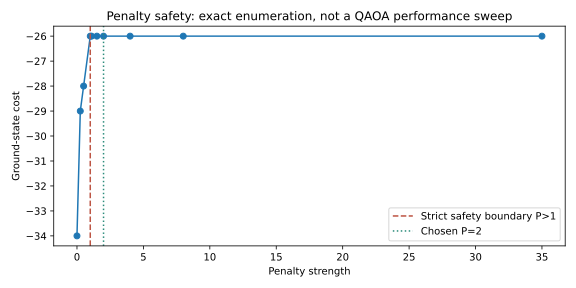

In [7]:
robustness = json.loads(Path("results/tables/robustness_summary.json").read_text())
for summary in robustness["summary"]:
    print(summary)
print(Path("results/tables/penalty_sweep.json").read_text())
display({"image/svg+xml":Path("results/figures/penalty_safety.svg").read_text()},raw=True)